# STIMTEC – Verification of the OGS T model (heat conduction in a granite disk) – step boundary temperature

This notebook verifies the OpenGeoSys `HEAT_CONDUCTION` model `T_granite_step.prj` against the analytical solution
for transient heat conduction in a disk with a fixed boundary temperature.

| | |
|---|---|
| Domain | disk, $R = 0.1$ m, embedded inner circle $a = 0.066$ m, centre node $(0,0,0)$ |
| Initial condition | $T(r,0) = T_0 = 293$ K |
| Boundary condition | $T(R,t) = T_b = 323$ K (Dirichlet) |
| Granite | $\rho = 2700$ kg/m³, $\lambda = 2.8$ W/(m K), $c_p = 790$ J/(kg K) |
| Time | $0 \le t \le 21600$ s, $\Delta t = 30$ s, backward Euler |

**Steps:** (1) run OGS, (2) analytical solution, (3) centre time series, (4) radial profiles,
(5) error norms over time, (6) mean temperature in the inner disk $r \le a$ (later needed for the volumetric strain),
(7) time-step convergence study.

Requirements: `ogs` (e.g. `pip install ogs`), `numpy`, `scipy`, `matplotlib`, `vtk`.
The notebook expects `T_granite_step.prj` and the mesh files (`domain.vtu`, `outer_boundary.vtu`, `inner_circle.vtu`,
`inner_disk.vtu`, `center.vtu`) in the same folder.

In [1]:
import shutil, subprocess, time
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import vtk
from vtk.util.numpy_support import vtk_to_numpy
from scipy.special import j0, j1, jn_zeros

HERE = Path.cwd()
PRJ = HERE / "T_granite_step.prj"
OUT = HERE / "results_step"
assert PRJ.exists(), f"{PRJ} not found - start the notebook in the folder containing the prj"

## 1 Parameters (read from the project file)

Material and boundary values are taken directly from `T_granite_step.prj`, so the analytical solution
always uses the same values as the simulation.

In [2]:
root = ET.parse(PRJ).getroot()
prop = {p.findtext("name"): float(p.findtext("value"))
        for p in root.iter("property")}
par = {p.findtext("name"): float(p.findtext("value"))
       for p in root.find("parameters") if p.findtext("type") == "Constant"}

lam, cp, rho = prop["thermal_conductivity"], prop["specific_heat_capacity"], prop["density"]
T0, Tb = par["T0"], par["T_outer"]
R, a_in = 0.1, 0.066
kappa = lam / (rho * cp)          # thermal diffusivity [m2/s]
t_char = R**2 / kappa             # characteristic diffusion time [s]

print(f"lambda = {lam} W/(m K), cp = {cp} J/(kg K), rho = {rho} kg/m3")
print(f"T0 = {T0} K, Tb = {Tb} K")
print(f"kappa = {kappa:.4e} m2/s,  R^2/kappa = {t_char:.0f} s = {t_char/3600:.2f} h")

lambda = 2.8 W/(m K), cp = 790.0 J/(kg K), rho = 2700.0 kg/m3
T0 = 293.0 K, Tb = 323.0 K
kappa = 1.3127e-06 m2/s,  R^2/kappa = 7618 s = 2.12 h


## 2 Run OGS

In [3]:
def run_ogs(prj, outdir):
    outdir = Path(outdir)
    if outdir.exists():
        shutil.rmtree(outdir)
    outdir.mkdir(parents=True)
    t = time.time()
    res = subprocess.run(["ogs", str(prj), "-o", str(outdir)],
                         cwd=HERE, capture_output=True, text=True)
    (outdir / "ogs_log.txt").write_text(res.stdout + res.stderr)
    if res.returncode != 0:
        print(res.stdout[-3000:], res.stderr[-3000:])
        raise RuntimeError("OGS run failed")
    print(f"OGS finished in {time.time() - t:.1f} s -> {outdir}")

run_ogs(PRJ, OUT)

OGS finished in 30.7 s -> C:\User\94-CLD\stimtec\T_model\mesh\results_step


### Helper functions for reading the results

In [4]:
def read_vtu(f):
    r = vtk.vtkXMLUnstructuredGridReader()
    r.SetFileName(str(f)); r.Update()
    g = r.GetOutput()
    pts = vtk_to_numpy(g.GetPoints().GetData())
    T = vtk_to_numpy(g.GetPointData().GetArray("temperature"))
    return pts, T, g

def read_pvd(outdir, meshname):
    # returns list of (time, vtu path)
    pvd = Path(outdir) / f"T_granite_{meshname}.pvd"
    return [(float(d.get("timestep")), Path(outdir) / d.get("file"))
            for d in ET.parse(pvd).getroot().iter("DataSet")]

def element_areas(g):
    # area of each triangle (vtkCellSizeFilter)
    f = vtk.vtkCellSizeFilter(); f.SetInputData(g)
    f.ComputeAreaOn(); f.ComputeLengthOff(); f.ComputeVolumeOff(); f.ComputeVertexCountOff()
    f.Update()
    return vtk_to_numpy(f.GetOutput().GetCellData().GetArray("Area"))

def mean_T_fe(g, T):
    # area-weighted mean of the linear FE field (exact for P1 triangles)
    A = element_areas(g)
    conn = vtk_to_numpy(g.GetCells().GetConnectivityArray()).reshape(-1, 3)
    return np.sum(A * T[conn].mean(axis=1)) / A.sum()

## 3 Analytical solution

Transient heat conduction in a disk (radial symmetry):

$$
\frac{\partial T}{\partial t} = \kappa \left( \frac{\partial^2 T}{\partial r^2} + \frac{1}{r}\frac{\partial T}{\partial r} \right),
\qquad \kappa = \frac{\lambda}{\rho c_p},
$$

with $T(r,0)=T_0$, $T(R,t)=T_b$ and $T$ finite at $r=0$. Separation of variables gives (Carslaw & Jaeger, 1959, §7.4)

$$
T(r,t) = T_b + (T_0 - T_b)\sum_{n=1}^{\infty} \frac{2}{\alpha_n J_1(\alpha_n)}\,
J_0\!\left(\alpha_n \frac{r}{R}\right) \exp\!\left(-\alpha_n^2 \frac{\kappa t}{R^2}\right),
$$

where $\alpha_n$ are the positive roots of $J_0(\alpha)=0$.

The **mean temperature over the inner disk** $r \le a$ follows by integrating $J_0$
($\int_0^{x} s J_0(s)\,ds = x J_1(x)$):

$$
\bar T_a(t) = \frac{2}{a^2}\int_0^a T\,r\,dr
= T_b + (T_0 - T_b)\sum_{n=1}^{\infty} \frac{2}{\alpha_n J_1(\alpha_n)}\,
\frac{2 J_1(\alpha_n a/R)}{\alpha_n a/R}\exp\!\left(-\alpha_n^2 \frac{\kappa t}{R^2}\right).
$$

At $t \to 0$ the series converges slowly (step between initial and boundary value), so 400 terms are used.

In [5]:
alpha = jn_zeros(0, 400)
coef = 2.0 / (alpha * j1(alpha))

def T_analytical(r, t):
    r = np.atleast_1d(r).astype(float)
    damp = np.exp(-alpha**2 * kappa * t / R**2)
    return Tb + (T0 - Tb) * (j0(np.outer(r / R, alpha)) @ (coef * damp))

def T_mean_analytical(a, t):
    x = alpha * a / R
    damp = np.exp(-alpha**2 * kappa * t / R**2)
    return Tb + (T0 - Tb) * np.sum(coef * 2 * j1(x) / x * damp)

# sanity checks
print("T(r=R, t=100 s)   =", T_analytical(R, 100.0)[0], "(should be Tb)")
print("T(r=0, t=1 s)     =", T_analytical(0.0, 1.0)[0], "(should be ~T0)")
print("mean T(a=R, t=1e6)=", T_mean_analytical(R, 1e6), "(should be Tb)")

T(r=R, t=100 s)   = 323.0 (should be Tb)
T(r=0, t=1 s)     = 293.0 (should be ~T0)
mean T(a=R, t=1e6)= 323.0 (should be Tb)


## 4 Temperature at the centre node $(0,0,0)$

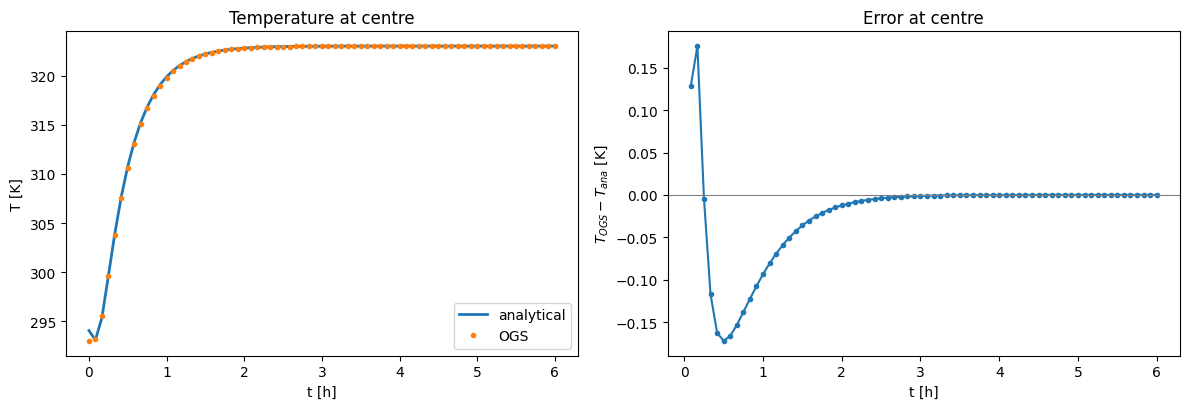

max |error| at centre (t > 0): 0.176 K


In [6]:
center = read_pvd(OUT, "center")
tc = np.array([t for t, _ in center])
Tc = np.array([read_vtu(f)[1][0] for _, f in center])
Tc_ana = np.array([T_analytical(0.0, t)[0] for t in tc])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(tc / 3600, Tc_ana, "-", lw=2, label="analytical")
ax[0].plot(tc / 3600, Tc, "o", ms=3, label="OGS")
ax[0].set(xlabel="t [h]", ylabel="T [K]", title="Temperature at centre")
ax[0].legend()
ax[1].plot(tc[1:] / 3600, (Tc - Tc_ana)[1:], "-o", ms=3)
ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].set(xlabel="t [h]", ylabel=r"$T_{OGS} - T_{ana}$ [K]", title="Error at centre")
plt.tight_layout(); plt.show()

print(f"max |error| at centre (t > 0): {np.abs(Tc - Tc_ana)[1:].max():.3f} K")

## 5 Radial profiles

All nodes of the bulk mesh are plotted against their radius $r=\sqrt{x^2+y^2}$.
The scatter at a given $r$ shows how well the mesh preserves radial symmetry.

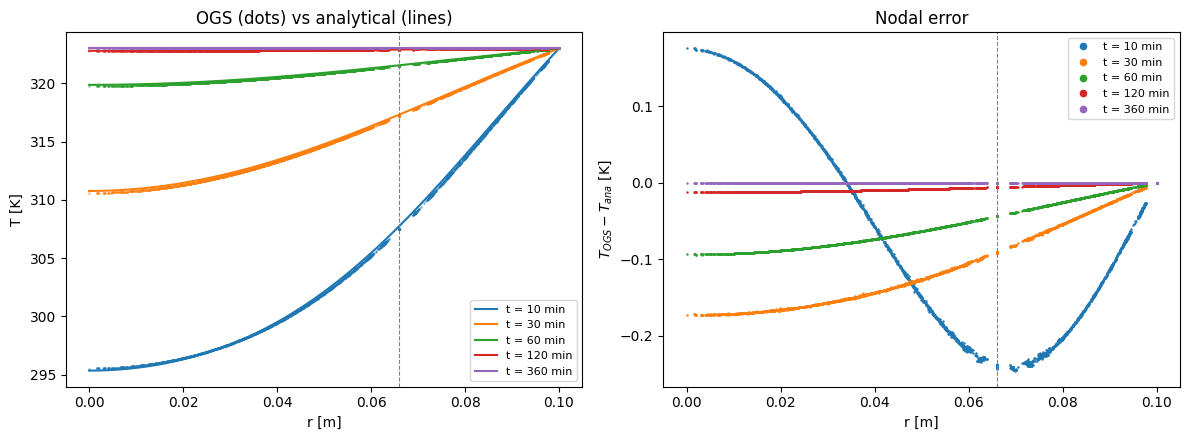

In [7]:
domain = dict(read_pvd(OUT, "domain"))
t_plot = [600, 1800, 3600, 7200, 21600]
rr = np.linspace(0, R, 300)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for t in t_plot:
    pts, T, _ = read_vtu(domain[float(t)])
    r = np.hypot(pts[:, 0], pts[:, 1])
    l, = ax[0].plot(rr, T_analytical(rr, t), "-", label=f"t = {t/60:.0f} min")
    ax[0].plot(r, T, ".", ms=1.5, color=l.get_color(), alpha=0.5)
    ax[1].plot(r, T - T_analytical(r, t), ".", ms=1.5, color=l.get_color(), label=f"t = {t/60:.0f} min")
for a_ in ax:
    a_.axvline(a_in, ls="--", color="0.5", lw=0.8)
ax[0].set(xlabel="r [m]", ylabel="T [K]", title="OGS (dots) vs analytical (lines)")
ax[1].set(xlabel="r [m]", ylabel=r"$T_{OGS} - T_{ana}$ [K]", title="Nodal error")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8, markerscale=6)
plt.tight_layout(); plt.show()

## 6 Error norms over time

For each output time:

* maximum nodal error $\;e_\infty = \max_i |T_i - T_{ana}(r_i,t)|$
* discrete relative $L_2$ error of the temperature change
  $\;e_{L_2} = \lVert T - T_{ana}\rVert_2 \,/\, \lVert T_{ana} - T_0 \rVert_2$

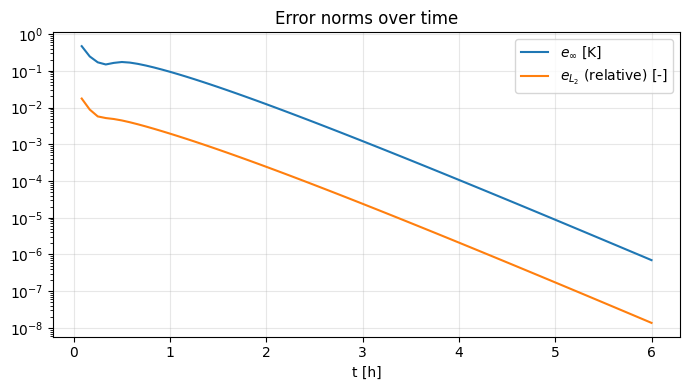

 t [s]     e_inf [K]   e_L2,rel [-]
   600      0.2455     8.80e-03
  1800      0.1732     4.45e-03
  3600      0.0938     1.95e-03
  7200      0.0123     2.43e-04
 14400      0.0001     2.11e-06
 21600      0.0000     1.38e-08


In [8]:
rows = []
for t, f in read_pvd(OUT, "domain"):
    if t == 0:
        continue
    pts, T, _ = read_vtu(f)
    Ta = T_analytical(np.hypot(pts[:, 0], pts[:, 1]), t)
    rows.append((t, np.abs(T - Ta).max(),
                 np.linalg.norm(T - Ta) / np.linalg.norm(Ta - T0)))
err = np.array(rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(err[:, 0] / 3600, err[:, 1], label=r"$e_\infty$ [K]")
ax.semilogy(err[:, 0] / 3600, err[:, 2], label=r"$e_{L_2}$ (relative) [-]")
ax.set(xlabel="t [h]", title="Error norms over time"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(" t [s]     e_inf [K]   e_L2,rel [-]")
for t, ei, el in err:
    if t in (600, 1800, 3600, 7200, 14400, 21600):
        print(f"{t:6.0f}   {ei:9.4f}   {el:10.2e}")

## 7 Mean temperature of the inner disk $r \le 0.066$ m

This quantity is the basis for the volumetric (thermal) strain later on,
e.g. $\varepsilon_V \approx \beta_T\,(\bar T_a - T_0)$ with the volumetric thermal expansion coefficient $\beta_T$.
The OGS value is the exact area integral of the linear FE field over the `inner_disk` sub-mesh.

inner disk area: FE 1.367645e-02 m2 vs pi a^2 1.368478e-02 m2 (-0.061 %)


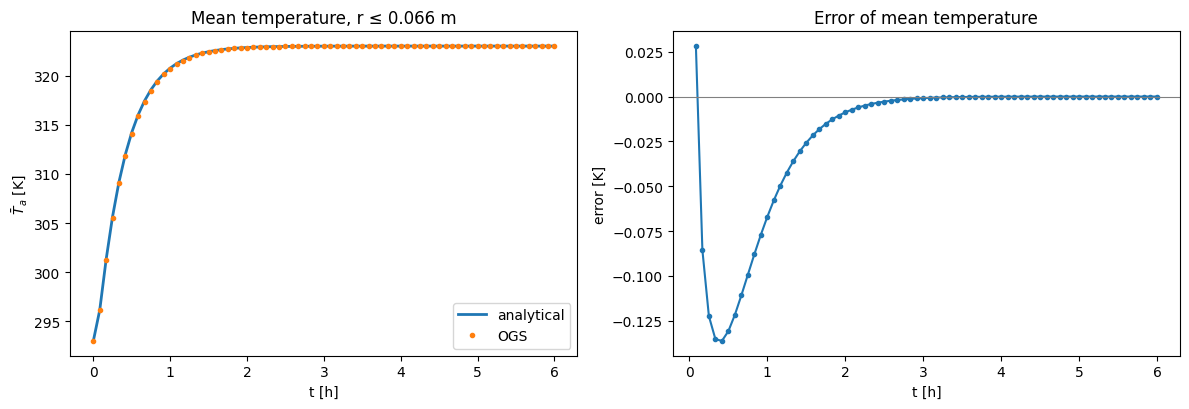

max |error| of mean T (t > 0): 0.1362 K


In [9]:
disk = read_pvd(OUT, "inner_disk")
td = np.array([t for t, _ in disk])
Tm = np.array([mean_T_fe(read_vtu(f)[2], read_vtu(f)[1]) for _, f in disk])
Tm_ana = np.array([T_mean_analytical(a_in, t) for t in td])

_, _, g0 = read_vtu(disk[0][1])
A_fe = element_areas(g0).sum()
print(f"inner disk area: FE {A_fe:.6e} m2 vs pi a^2 {np.pi*a_in**2:.6e} m2 "
      f"({100*(A_fe/(np.pi*a_in**2)-1):+.3f} %)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(td / 3600, Tm_ana, "-", lw=2, label="analytical")
ax[0].plot(td / 3600, Tm, "o", ms=3, label="OGS")
ax[0].set(xlabel="t [h]", ylabel=r"$\bar T_a$ [K]", title="Mean temperature, r ≤ 0.066 m"); ax[0].legend()
ax[1].plot(td[1:] / 3600, (Tm - Tm_ana)[1:], "-o", ms=3)
ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].set(xlabel="t [h]", ylabel="error [K]", title="Error of mean temperature")
plt.tight_layout(); plt.show()
print(f"max |error| of mean T (t > 0): {np.abs(Tm - Tm_ana)[1:].max():.4f} K")

## 8 Time-step convergence study

Backward Euler is first-order in time, so the error at a fixed time should drop roughly linearly with $\Delta t$
until the spatial discretisation error dominates. The project file is copied with modified time stepping
($t_{end} = 1800$ s, output only at the end) and run for several $\Delta t$.
Set `RUN_STUDY = False` to skip (≈ 10–30 s runtime).

OGS finished in 1.4 s -> C:\User\94-CLD\stimtec\T_model\mesh\results_dtstudy_step\dt_120
OGS finished in 2.1 s -> C:\User\94-CLD\stimtec\T_model\mesh\results_dtstudy_step\dt_60
OGS finished in 2.8 s -> C:\User\94-CLD\stimtec\T_model\mesh\results_dtstudy_step\dt_30
OGS finished in 4.7 s -> C:\User\94-CLD\stimtec\T_model\mesh\results_dtstudy_step\dt_15
OGS finished in 8.9 s -> C:\User\94-CLD\stimtec\T_model\mesh\results_dtstudy_step\dt_7.5


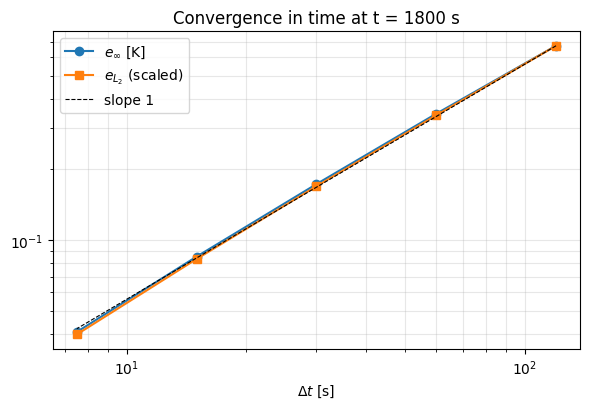

 dt [s]   e_inf [K]   e_L2,rel   order(e_inf)
   120      0.6720    1.76e-02   
    60      0.3452    8.92e-03   0.96
    30      0.1732    4.45e-03   1.00
    15      0.0851    2.18e-03   1.02
   7.5      0.0407    1.04e-03   1.06


In [10]:
RUN_STUDY = True
t_check = 1800.0
dts = [120, 60, 30, 15, 7.5]

def make_variant(dt, t_end, name):
    tree = ET.parse(PRJ); r = tree.getroot()
    ts = r.find(".//time_stepping")
    ts.find("t_end").text = str(t_end)
    pair = ts.find("timesteps/pair")
    pair.find("repeat").text = str(int(round(t_end / dt)))
    pair.find("delta_t").text = str(dt)
    out = r.find(".//output")
    out.find("timesteps/pair/each_steps").text = str(int(round(t_end / dt)))
    fot = out.find("fixed_output_times")
    if fot is not None:
        out.remove(fot)
    meshes = out.find("meshes")
    for m in list(meshes):
        if m.text.strip() != "domain":
            meshes.remove(m)
    out.find("prefix").text = "T_granite_{:meshname}"
    p = HERE / f"{name}.prj"
    tree.write(p, encoding="ISO-8859-1", xml_declaration=True)
    return p

if RUN_STUDY:
    conv = []
    for dt in dts:
        p = make_variant(dt, t_check, f"_dtstudy_step_{dt:g}")
        od = HERE / "results_dtstudy_step" / f"dt_{dt:g}"
        run_ogs(p, od); p.unlink()
        t_last, f_last = read_pvd(od, "domain")[-1]
        pts, T, _ = read_vtu(f_last)
        Ta = T_analytical(np.hypot(pts[:, 0], pts[:, 1]), t_last)
        conv.append((dt, np.abs(T - Ta).max(), np.linalg.norm(T - Ta) / np.linalg.norm(Ta - T0)))
    conv = np.array(conv)

    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.loglog(conv[:, 0], conv[:, 1], "o-", label=r"$e_\infty$ [K]")
    ax.loglog(conv[:, 0], conv[:, 2] * conv[0, 1] / conv[0, 2], "s-", label=r"$e_{L_2}$ (scaled)")
    ref = conv[0, 1] * (conv[:, 0] / conv[0, 0])
    ax.loglog(conv[:, 0], ref, "k--", lw=0.8, label="slope 1")
    ax.set(xlabel=r"$\Delta t$ [s]", title=f"Convergence in time at t = {t_check:.0f} s"); ax.legend()
    ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

    print(" dt [s]   e_inf [K]   e_L2,rel   order(e_inf)")
    for i, (dt, ei, el) in enumerate(conv):
        o = "" if i == 0 else f"{np.log(conv[i-1,1]/ei)/np.log(conv[i-1,0]/dt):.2f}"
        print(f"{dt:6g}   {ei:9.4f}   {el:9.2e}   {o}")

## 9 Summary

In [11]:
print("Verification summary - OGS HEAT_CONDUCTION vs analytical (Bessel series)")
print(f"  centre node     : max |error| = {np.abs(Tc - Tc_ana)[1:].max():.3f} K")
print(f"  all nodes       : max |error| = {err[:,1].max():.3f} K (at t = {err[err[:,1].argmax(),0]:.0f} s)")
print(f"  inner-disk mean : max |error| = {np.abs(Tm - Tm_ana)[1:].max():.4f} K")
print(f"  end state       : T_centre = {Tc[-1]:.4f} K (Tb = {Tb} K)")
if RUN_STUDY:
    order = np.log(conv[0,1]/conv[-1,1]) / np.log(conv[0,0]/conv[-1,0])
    print(f"  time convergence: mean observed order {order:.2f} (backward Euler: 1)")

Verification summary - OGS HEAT_CONDUCTION vs analytical (Bessel series)
  centre node     : max |error| = 0.176 K
  all nodes       : max |error| = 0.467 K (at t = 300 s)
  inner-disk mean : max |error| = 0.1362 K
  end state       : T_centre = 323.0000 K (Tb = 323.0 K)
  time convergence: mean observed order 1.01 (backward Euler: 1)


**Interpretation.** The largest errors occur at early times close to the outer boundary, where the step
between $T_0$ and $T_b$ creates steep gradients that the first-order time scheme and the element size
cannot fully resolve. Errors decay quickly as the temperature field smooths out, and the model reaches
the steady state $T = T_b$. Further reduction is possible with smaller $\Delta t$ in the first minutes
(e.g. graded time steps) and/or a finer mesh near $r = R$ (`make_circle_mesh.py --lc ...`).